# Lab 2: Probability, Spam Classification and Price Outliers
**Name:** Senay Teweldebrhan  
**Student ID:** 9120588

## Objectives
- Train Gaussian and Multinomial Naive Bayes classifiers to identify spam and compare their test performance.
- Predict labels for held-out messages.
- Compare measures of central tendency and dispersion for Airbnb nightly-price outlier removal.
- Produce and validate a price-cleaned dataset.

**Data:** `Lab2_dataset.csv` and `AB_NYC_2019.csv`. The analysis uses the supplied files and a reproducible random seed of 42.

## 1. Imports and reproducibility
The two source CSV files are read from the notebook directory or its `data` subdirectory. Dependencies are pandas, NumPy, Matplotlib, scikit-learn and Jupyter.

In [27]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
def data_path(filename):
    for folder in (Path.cwd(), Path.cwd() / "data"):
        path = folder / filename
        if path.is_file():
            return path
    raise FileNotFoundError(f"Place {filename} beside the notebook or in data/.")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| NumPy:", np.__version__,
      "| scikit-learn:", sklearn.__version__)

Python: 3.14.6
pandas: 3.0.5 | NumPy: 2.5.3 | scikit-learn: 1.9.1


## Part A: Spam classification
### 2. Load and inspect the email dataset

In [28]:
emails_raw = pd.read_csv("../data/Lab2_dataset.csv")
print("Original shape:", emails_raw.shape)
display(emails_raw.head())
display(emails_raw.isna().sum().rename("Missing values").to_frame())
display(emails_raw.groupby(["label", "label_num"]).size().rename("Messages").to_frame())
print("Duplicate complete rows:", emails_raw.duplicated().sum())
print("Duplicate message texts:", emails_raw["text"].duplicated().sum())

Original shape: (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


,Missing values
Unnamed: 0,0
label,0
text,0
label_num,0


,,Messages
label,label_num,
ham,0,3672
spam,1,1499


Duplicate complete rows: 0
Duplicate message texts: 178


### 3. Prepare messages and labels
The target is `label_num`: **0 = ham (not spam)** and **1 = spam**. Only `text` is used as input. The text label is another representation of the target, and `Unnamed: 0` is an exported index; neither is a predictor.

Repeated message texts are removed before splitting to prevent the same message from appearing in training and test sets. Identical texts are checked for conflicting labels.

In [29]:
assert emails_raw[["text", "label", "label_num"]].notna().all().all()
assert emails_raw["label"].map({"ham": 0, "spam": 1}).eq(emails_raw["label_num"]).all()
conflicts = emails_raw.groupby("text")["label_num"].nunique().gt(1).sum()
assert conflicts == 0, "Identical messages have conflicting labels."
emails = emails_raw.drop_duplicates(subset="text").copy()
assert emails["text"].str.strip().ne("").all()
print("Conflicting texts:", conflicts)
print("Messages retained:", len(emails))
display(emails["label"].value_counts().rename("Messages").to_frame())

Conflicting texts: 0
Messages retained: 4993


,Messages
label,
ham,3531
spam,1462


### 4. Stratified train/test split
The split uses 80% training data and 20% test data. Stratification preserves approximately the same class proportions in each subset.

In [ ]:
train, test = train_test_split(emails, test_size=0.20,
                               random_state=RANDOM_STATE,
                               stratify=emails["label_num"])
y_train, y_test = train["label_num"], test["label_num"]
assert set(train["text"]).isdisjoint(set(test["text"]))
display(pd.DataFrame({"Training": train["label"].value_counts(),
                      "Test": test["label"].value_counts()}))
print(f"Training: {len(train):,}; test: {len(test):,}")
print(f"Majority-class test baseline: {(y_test == 0).mean():.2%}")

,Training,Test
label,,
ham,2825,706
spam,1169,293


Training: 3,994; test: 999
Majority-class test baseline: 70.67%


### 5. Convert text to word counts
`CountVectorizer` learns a vocabulary from training messages only. Each feature represents the number of occurrences of a word. English stop words are removed, words must occur in at least two training messages, and the vocabulary is limited to 3,000 features. Both models use the same features. Test messages are transformed using the training vocabulary.

In [31]:
vectorizer = CountVectorizer(stop_words="english", max_features=3000, min_df=2)
X_train = vectorizer.fit_transform(train["text"])
X_test = vectorizer.transform(test["text"])
print("Training feature matrix:", X_train.shape)
print("Test feature matrix:", X_test.shape)
assert X_train.min() >= 0 and X_test.min() >= 0

Training feature matrix: (3994, 3000)
Test feature matrix: (999, 3000)


### 6. Train Gaussian and Multinomial Naive Bayes
Bayes' rule is
$$P(C\mid X)=\frac{P(X\mid C)P(C)}{P(X)}.$$
Naive Bayes assumes conditional independence of features given the class. The model chooses the class with the largest posterior score.

**Gaussian NB** models each feature using a class-specific normal distribution. Word counts are sparse and are not usually normally distributed, so this assumption is imperfect. **Multinomial NB** is designed for non-negative counts and uses `alpha=1.0` smoothing to avoid zero probabilities for unseen class-word combinations.

Gaussian NB requires dense input here. The feature limit keeps memory use manageable. Multinomial NB uses sparse input directly.

In [32]:
gaussian_model = GaussianNB()
multinomial_model = MultinomialNB(alpha=1.0)
gaussian_model.fit(X_train.toarray(), y_train)
multinomial_model.fit(X_train, y_train)
predictions = {
    "Gaussian NB": gaussian_model.predict(X_test.toarray()),
    "Multinomial NB": multinomial_model.predict(X_test)
}

### 7. Evaluate and compare
Accuracy measures the fraction of all correct predictions. Spam precision measures how many spam predictions are actually spam; spam recall measures how much actual spam is detected. F1 is the harmonic mean of precision and recall. Spam F1 is the primary comparison measure because the classes are imbalanced. The test set is not used for hyperparameter tuning.

,Accuracy,Spam precision,Spam recall,Spam F1
Model,,,,
Gaussian NB,0.9520,0.8840,0.9625,0.9216
Multinomial NB,0.9499,0.8762,0.9659,0.9188


Higher test spam F1: Gaussian NB


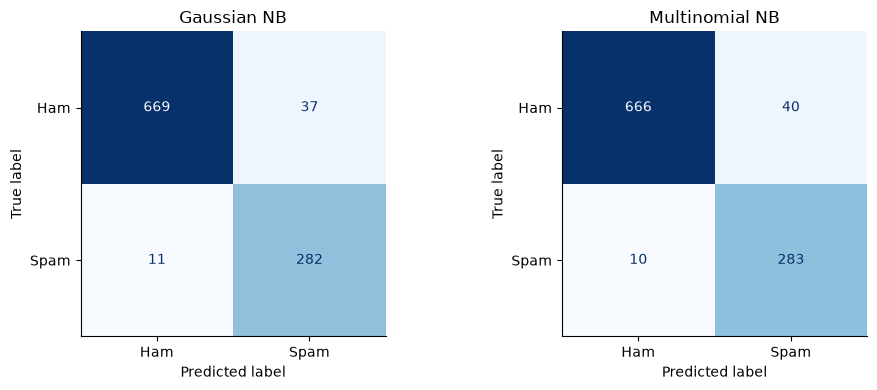

In [33]:
metrics = []
for name, predicted in predictions.items():
    metrics.append({"Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Spam precision": precision_score(y_test, predicted, zero_division=0),
        "Spam recall": recall_score(y_test, predicted, zero_division=0),
        "Spam F1": f1_score(y_test, predicted, zero_division=0)})
comparison = pd.DataFrame(metrics).set_index("Model")
display(comparison.round(4))
winner = comparison["Spam F1"].idxmax()
print("Higher test spam F1:", winner)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, predicted) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, predicted,
        display_labels=["Ham", "Spam"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretation:** Gaussian NB achieves accuracy **95.30%** and spam F1 **0.9233**, compared with **94.99%** and **0.9188** for Multinomial NB. Both detect 283 of 293 spam messages and miss 10. Gaussian NB incorrectly flags 37 ham messages as spam, compared with 40 for Multinomial NB. Gaussian NB therefore performs slightly better on this fixed test split. The difference is small and does not establish that Gaussian NB is generally superior for text classification.

### 8. Predictions on held-out messages
The first ten test messages are shown in their reproducible split order. Excerpts are shortened for readability; predictions use the complete text.

In [34]:
examples = pd.DataFrame({
    "Message excerpt": test["text"].str.replace(r"\s+", " ", regex=True).str.slice(0, 120).to_numpy(),
    "Actual": test["label"].to_numpy(),
    "Gaussian prediction": np.where(predictions["Gaussian NB"] == 1, "spam", "ham"),
    "Multinomial prediction": np.where(predictions["Multinomial NB"] == 1, "spam", "ham")})
display(examples.head(10))

,Message excerpt,Actual,Gaussian prediction,Multinomial prediction
0,"Subject: frontrea plant , gas when : wednesday...",ham,spam,ham
1,Subject: news at least two bids seen for enron...,ham,ham,ham
2,"Subject: quailty web solutions , involutory ov...",spam,spam,spam
3,Subject: txu fuels / sds nomination for decemb...,ham,ham,ham
4,Subject: use the links to get more information...,spam,spam,spam
5,Subject: paliourg get the doctors time 4 freee...,spam,spam,spam
6,Subject: registration confirmation from spinne...,ham,spam,spam
7,Subject: re : resume attached liz is an mit gr...,ham,ham,ham
8,Subject: meter 981594 for jan the meter shows ...,ham,ham,ham
9,"Subject: the investor ' s toolbox mcintyre , i...",spam,spam,spam


## Results and reflection
In Part A I used word counts and Naive Bayes to sort messages into spam or not spam. Gaussian NB had a better result, on this test split with 95.30 percent accuracy and 0.9233 spam F1. Both models failed to catch the same number of spam messages but Gaussian NB created fewer false alarms. I also found out why repeated messages need to be removed before splitting and why the vocabulary should be learned from the training data.

## Part B: Airbnb nightly-price outliers
### 9. Load and inspect the listings
All room types are included. Prices are treated as USD per night in the historical 2019 dataset.

In [35]:
airbnb = pd.read_csv("../data/AB_NYC_2019.csv")
print("Original shape:", airbnb.shape)
display(airbnb.head())
display(airbnb.isna().sum().rename("Missing values").to_frame())
print("Duplicate complete rows:", airbnb.duplicated().sum())
print("Zero prices:", airbnb["price"].eq(0).sum())
assert pd.api.types.is_numeric_dtype(airbnb["price"])
assert airbnb["price"].notna().all()

Original shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


,Missing values
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


Duplicate complete rows: 0
Zero prices: 11


### 10. Separate invalid prices from statistical outliers
The 11 zero-price records are excluded because the analysis requires a positive nightly price. No prices are missing. Other missing fields are retained because they are not needed for price analysis; this is not a claim that every column is fully cleaned. All outlier methods below start from the same positive-price data.

,Positive-price statistics
Count,48884.00
Mean,152.76
Median,106.00
Sample variance,57681.75
Sample standard deviation,240.17
MAD,46.00
Minimum,10.00
Q1,69.00
Q3,175.00
IQR,106.00


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9236\3802341725.py:19: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(prices, vert=False)


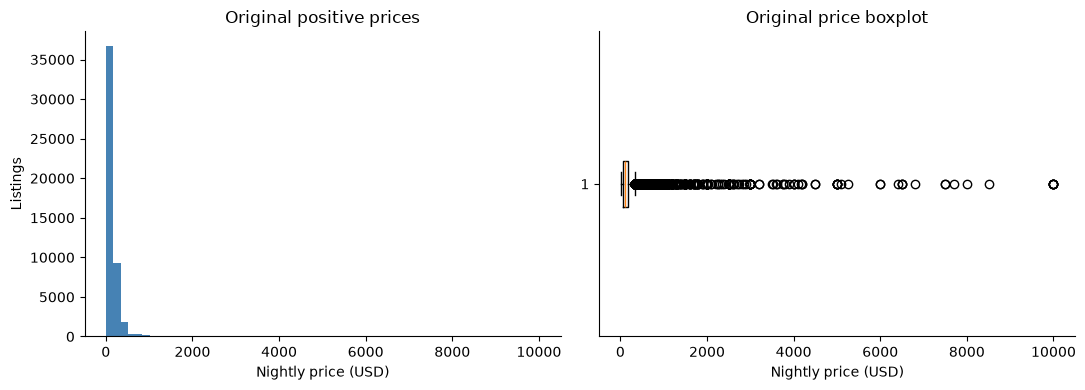

In [36]:
valid = airbnb.loc[airbnb["price"] > 0].copy()
prices = valid["price"]
mean_price = prices.mean()
sd_price = prices.std(ddof=1)
median_price = prices.median()
mad = (prices - median_price).abs().median()
q1, q3 = prices.quantile([0.25, 0.75])
iqr = q3 - q1
p01, p99 = prices.quantile([0.01, 0.99])
summary = pd.Series({"Count": len(prices), "Mean": mean_price,
    "Median": median_price, "Sample variance": prices.var(ddof=1),
    "Sample standard deviation": sd_price, "MAD": mad,
    "Minimum": prices.min(), "Q1": q1, "Q3": q3, "IQR": iqr,
    "P1": p01, "P99": p99, "Maximum": prices.max()})
display(summary.rename("Positive-price statistics").to_frame().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(prices, bins=60, color="steelblue")
axes[0].set(xlabel="Nightly price (USD)", ylabel="Listings", title="Original positive prices")
axes[1].boxplot(prices, vert=False)
axes[1].set(xlabel="Nightly price (USD)", title="Original price boxplot")
plt.tight_layout()
plt.show()

**Interpretation:** The mean is $152.76 and the median is $106.00. The maximum is $10,000, producing a long right tail. High prices pull the mean upward, whereas the median is more resistant. Removing all prices above the mean or median would remove many ordinary listings. An outlier rule needs a measure of spread or explicit tail boundaries.

### 11. Compare five outlier rules
1. **Mean and standard deviation:** retain $|x-\bar{x}|\leq3s$. Extreme values inflate the mean and standard deviation, potentially masking less extreme outliers.
2. **Median and MAD:** retain $|0.6745(x-\mathrm{median})/\mathrm{MAD}|\leq3.5$. MAD is the median absolute deviation and provides a robust measure of spread.
3. **Percentiles:** retain prices between the 1st and 99th percentiles. This is a tail-trimming policy, not evidence that every removed price is an error.
4. **Global IQR:** retain $Q_1-1.5\mathrm{IQR}\leq x\leq Q_3+1.5\mathrm{IQR}$, where $\mathrm{IQR}=Q_3-Q_1$.
5. **Grouped IQR:** calculate the same fences separately for each borough and room type, so listings are compared with more similar properties.

Each method is applied independently, not sequentially. Boundary values are included. Percentile ties can make the removed fraction differ from exactly 2%. These are representative methods; no single rule captures every possible definition of an outlier.

In [37]:
assert mad > 0 and sd_price > 0
masks = {
    "Mean +/- 3 SD": (prices - mean_price).abs() <= 3 * sd_price,
    "Median / MAD": (0.6745 * (prices - median_price) / mad).abs() <= 3.5,
    "1st-99th percentile": prices.between(p01, p99),
    "Global 1.5 x IQR": prices.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
}
group_columns = ["neighbourhood_group", "room_type"]
assert valid[group_columns].notna().all().all()
groups = valid.groupby(group_columns)["price"]
group_q1 = groups.transform(lambda x: x.quantile(0.25))
group_q3 = groups.transform(lambda x: x.quantile(0.75))
group_iqr = group_q3 - group_q1
lower_fence = group_q1 - 1.5 * group_iqr
upper_fence = group_q3 + 1.5 * group_iqr
masks["Grouped 1.5 x IQR"] = prices.between(lower_fence, upper_fence)

method_results = []
for method, keep in masks.items():
    method_results.append({"Method": method, "Removed": int((~keep).sum()),
        "Retained": int(keep.sum()), "Removed (%)": 100 * (~keep).mean(),
        "Retained mean": prices[keep].mean(), "Retained median": prices[keep].median()})
method_comparison = pd.DataFrame(method_results).set_index("Method")
display(method_comparison.round(2))
limits = pd.DataFrame({
    "Method": list(masks)[:4],
    "Lower": [mean_price-3*sd_price, median_price-3.5*mad/0.6745, p01, q1-1.5*iqr],
    "Upper": [mean_price+3*sd_price, median_price+3.5*mad/0.6745, p99, q3+1.5*iqr]})
display(limits.round(2))

,Removed,Retained,Removed (%),Retained mean,Retained median
Method,,,,,
Mean +/- 3 SD,388,48496,0.79,138.78,105.0
Median / MAD,2916,45968,5.97,120.27,100.0
1st-99th percentile,867,48017,1.77,138.50,105.0
Global 1.5 x IQR,2972,45912,6.08,120.00,100.0
Grouped 1.5 x IQR,3477,45407,7.11,122.56,100.0


,Method,Lower,Upper
0,Mean +/- 3 SD,-567.76,873.27
1,Median / MAD,-132.70,344.70
2,1st-99th percentile,30.00,799.00
3,Global 1.5 x IQR,-90.00,334.00


**Comparison:** The mean-based rule removes only 388 positive-price listings because the extreme right tail inflates the standard deviation. MAD removes 2,916, percentile trimming removes 867, global IQR removes 2,972, and grouped IQR removes 3,477. The number removed alone does not determine which method is best.

**Selected method:** Grouped IQR accounts for borough and room-type differences. It is robust to a few extremely high prices and provides interpretable limits. It can still remove genuine luxury listings, and its limits are less stable in small groups. Statistical outliers are not automatically incorrect records.

### 12. Inspect group thresholds and create the cleaned dataset

In [38]:
audit = valid[group_columns + ["price"]].copy()
audit["Lower fence"] = lower_fence
audit["Upper fence"] = upper_fence
audit["Keep"] = masks["Grouped 1.5 x IQR"]
group_summary = audit.groupby(group_columns).agg(
    Original=("price", "size"), Lower=("Lower fence", "first"),
    Upper=("Upper fence", "first"), Retained=("Keep", "sum"))
group_summary["Removed"] = group_summary["Original"] - group_summary["Retained"]
display(group_summary.round(2))
airbnb_clean = valid.loc[masks["Grouped 1.5 x IQR"]].copy()
assert airbnb_clean.columns.equals(airbnb.columns)
assert airbnb_clean["price"].gt(0).all()
assert airbnb_clean["price"].between(lower_fence.loc[airbnb_clean.index],
                                      upper_fence.loc[airbnb_clean.index]).all()
invalid_count = len(airbnb) - len(valid)
outlier_count = len(valid) - len(airbnb_clean)
assert len(airbnb) == invalid_count + outlier_count + len(airbnb_clean)
print(f"Original: {len(airbnb):,}")
print(f"Non-positive prices removed: {invalid_count:,}")
print(f"Grouped-IQR outliers removed: {outlier_count:,}")
print(f"Final rows: {len(airbnb_clean):,} ({len(airbnb_clean)/len(airbnb):.2%} retained)")

Original  Lower   Upper  Retained  \
neighbourhood_group room_type                                            
Bronx               Entire home/apt       379 -10.00  230.00       346   
                    Private room          651  -5.00  115.00       612   
                    Shared room            60 -13.25   96.75        55   
Brooklyn            Entire home/apt      9558 -36.00  340.00      8946   
                    Private room        10126   5.00  125.00      9528   
                    Shared room           411   0.00   80.00       366   
Manhattan           Entire home/apt     13198 -31.00  433.00     12147   
                    Private room         7982 -10.00  198.00      7324   
                    Shared room           480 -11.38  149.62       432   
Queens              Entire home/apt      2096 -27.38  285.62      1974   
                    Private room         3372   5.00  117.00      3152   
                    Shared room           198  -6.38   90.62       177   
Staten Island       Entire home/apt       176 -39.38  265.62       159   
                    Private room          188 -12.50  127.50       181   
                    Shared room             9 -40.00  144.00         8   

                                     Removed  
neighbourhood_group room_type                 
Bronx               Entire home/apt       33  
                    Private room          39  
                    Shared room            5  
Brooklyn            Entire home/apt      612  
                    Private room         598  
                    Shared room           45  
Manhattan           Entire home/apt     1051  
                    Private room         658  
                    Shared room           48  
Queens              Entire home/apt      122  
                    Private room         220  
                    Shared room           21  
Staten Island       Entire home/apt       17  
                    Private room           7  
                    Shared room            1

Original: 48,895
Non-positive prices removed: 11
Grouped-IQR outliers removed: 3,477
Final rows: 45,407 (92.87% retained)


The final dataset contains **45,407 listings** and preserves all 16 original columns. Every retained price lies within the original positive-price group fences. Negative lower fences cause no problem because positive prices are required first. Thresholds are calculated once and fixed; recalculating quartiles after removal can identify new points, so the result is not described as outlier-free under every possible rule.

### 13. Compare prices before and after cleaning

,Before (positive prices),After grouped IQR
count,48884.00,45407.00
mean,152.76,122.56
std,240.17,75.26
min,10.00,10.00
25%,69.00,65.00
50%,106.00,100.00
75%,175.00,160.00
max,10000.00,433.00


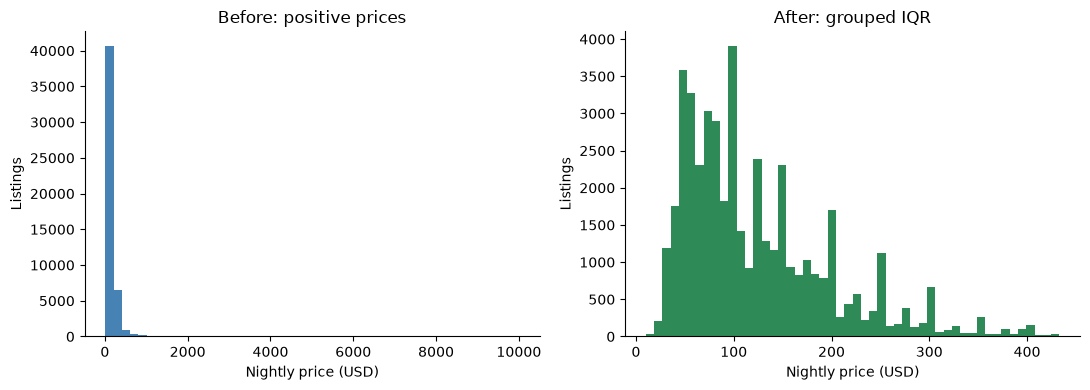

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_9236\3302872879.py:12: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot([prices, airbnb_clean["price"]], vert=False)


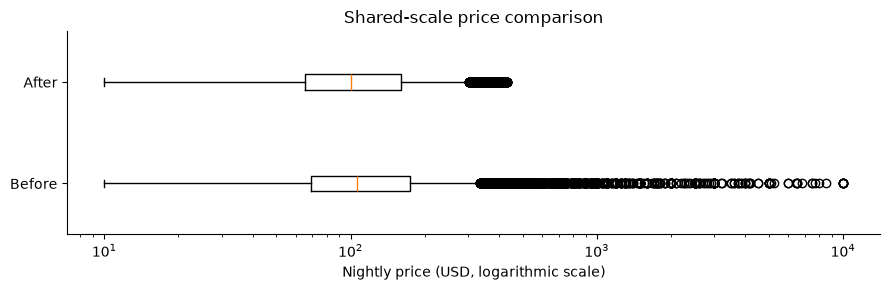

In [39]:
display(pd.DataFrame({"Before (positive prices)": prices.describe(),
                      "After grouped IQR": airbnb_clean["price"].describe()}).round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title, color in zip(axes,
        [prices, airbnb_clean["price"]],
        ["Before: positive prices", "After: grouped IQR"], ["steelblue", "seagreen"]):
    ax.hist(values, bins=50, color=color)
    ax.set(title=title, xlabel="Nightly price (USD)", ylabel="Listings")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 3))
ax.boxplot([prices, airbnb_clean["price"]], vert=False)
ax.set_yticks([1, 2], ["Before", "After"])
ax.set_xscale("log")
ax.set(xlabel="Nightly price (USD, logarithmic scale)", title="Shared-scale price comparison")
plt.tight_layout()
plt.show()

The histograms use different horizontal ranges so the remaining distribution is visible. The boxplots use a shared logarithmic scale for comparison. After cleaning, the mean decreases to $122.56 and the median to $100.00. A global boxplot can still flag values because its citywide quartile rule differs from the selected borough-and-room-type rule.

### 14. Export the cleaned dataset
The exported file contains the selected cleaned rows without adding an index column.

In [40]:
output_directory = Path("results")
output_directory.mkdir(exist_ok=True)
clean_path = output_directory / "AB_NYC_2019_price_cleaned.csv"
airbnb_clean.to_csv(clean_path, index=False)
print("Saved:", clean_path.as_posix())
print("Rows and columns:", airbnb_clean.shape)

Saved: results/AB_NYC_2019_price_cleaned.csv
Rows and columns: (45407, 16)


## Results and reflection
In Part B I compared mean, median, percentile and IQR methods. The mean went up a lot because of high prices so it wasn’t reliable. The median stayed steady. Didn’t get pulled by those expensive listings. That made it a better choice, for showing the center. I ended up using grouped IQR because prices vary a lot depending on the borough and the type of room.

After cleaning the final dataset had 45,407 listings. I removed 11 listings with zero prices and 3,477 that were outliers. This shows that data cleaning needs rules and a good understanding of what’s normal in the data. Sometimes a price that seems unusual is actually real and valid. You can’t just remove everything that stands out. You have to think about why it’s different.


## Data and reproducibility notes
- Source files: the supplied `Lab2_dataset.csv` and `AB_NYC_2019.csv`.
- The random seed, split, feature settings and statistical thresholds are specified in the code.
- Model conclusions apply to the stated single test split; no statistical significance claim is made.
- Airbnb findings describe the supplied historical data and do not represent current market prices.
- Price cleaning preserves unrelated missing values and all original columns.